In [1]:
import os
import sys
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Set random seed for reproducibility
np.random.seed(42)

print("Environment and libraries loaded successfully.")

Environment and libraries loaded successfully.


In [2]:
def load_corpus(filepath):
    """
    Load POS tagged corpus from file.
    Returns list of sentences, where each sentence is a list of (word, tag) tuples.
    """
    sentences = []
    current_sentence = []
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
            else:
                parts = line.split()
                if len(parts) >= 2:
                    current_sentence.append((parts[0], parts[1]))
                elif len(parts) == 1:
                    current_sentence.append((parts[0], 'UNK'))
        if current_sentence:
            sentences.append(current_sentence)
            
    return sentences

# File paths
train_path = 'hindi-train-pos.txt'
dev_path = 'hindi-dev-pos.txt'
test_path = 'hindi-test-pos.txt'

train_sents = load_corpus(train_path)
dev_sents = load_corpus(dev_path)
test_sents = load_corpus(test_path)

train_tokens = sum(len(s) for s in train_sents)
dev_tokens = sum(len(s) for s in dev_sents)
test_tokens = sum(len(s) for s in test_sents)

all_tags = sorted(list(set(tag for s in train_sents for word, tag in s)))

print(f"=== Dataset Summary ===")
print(f"Train : {len(train_sents):>6,d} sentences | {train_tokens:>7,d} tokens")
print(f"Dev   : {len(dev_sents):>6,d} sentences | {dev_tokens:>7,d} tokens")
print(f"Test  : {len(test_sents):>6,d} sentences | {test_tokens:>7,d} tokens")
print(f"Total BIS POS Tags ({len(all_tags)}): {all_tags}")

=== Dataset Summary ===
Train : 15,087 sentences | 325,710 tokens
Dev   :  1,866 sentences |  40,762 tokens
Test  :  1,910 sentences |  41,415 tokens
Total BIS POS Tags (24): ['CC_CCD', 'CC_CCS', 'DM_DMD', 'JJ', 'N_NN', 'N_NNP', 'N_NST', 'PR_PRF', 'PR_PRL', 'PR_PRP', 'PR_PRQ', 'PSP', 'QT_QTC', 'QT_QTF', 'QT_QTO', 'RB', 'RD_PUNC', 'RD_SYM', 'RP_INJ', 'RP_INTF', 'RP_NEG', 'RP_RPD', 'V_VAUX', 'V_VM']


In [3]:
def extract_token_features(sentence_words, i, prev_tag):
    """
    Extract feature dictionary for the token at index i in sentence_words.
    Supports either sentence as list of words or list of (word, tag) tuples.
    """
    word = sentence_words[i][0] if isinstance(sentence_words[i], tuple) else sentence_words[i]
    w_len = len(word)
    
    # 1. Prefixes up to length 4 (Prefix lengths 1, 2, 3, 4)
    # If not found, make feature = 'NULL'
    p1 = word[:1] if w_len >= 1 else 'NULL'
    p2 = word[:2] if w_len >= 2 else 'NULL'
    p3 = word[:3] if w_len >= 3 else 'NULL'
    p4 = word[:4] if w_len >= 4 else 'NULL'
    
    # 2. Suffixes up to length 4 (Suffix lengths 1, 2, 3, 4)
    # If not found, make feature = 'NULL'
    s1 = word[-1:] if w_len >= 1 else 'NULL'
    s2 = word[-2:] if w_len >= 2 else 'NULL'
    s3 = word[-3:] if w_len >= 3 else 'NULL'
    s4 = word[-4:] if w_len >= 4 else 'NULL'
    
    # 3. Context Features
    if i > 0:
        prev_w = sentence_words[i-1][0] if isinstance(sentence_words[i-1], tuple) else sentence_words[i-1]
    else:
        prev_w = 'BOS'
        
    if i < len(sentence_words) - 1:
        next_w = sentence_words[i+1][0] if isinstance(sentence_words[i+1], tuple) else sentence_words[i+1]
    else:
        next_w = 'EOS'
        
    # 4. Binary Length Feature: <= 4 is 'LESS', else 'MORE'
    length_feat = 'LESS' if w_len <= 4 else 'MORE'
    
    # Assemble feature dictionary
    features = {
        'word': word,
        'prefix_1': p1,
        'prefix_2': p2,
        'prefix_3': p3,
        'prefix_4': p4,
        'suffix_1': s1,
        'suffix_2': s2,
        'suffix_3': s3,
        'suffix_4': s4,
        'prev_word': prev_w,
        'current_word': word,
        'next_word': next_w,
        'length_feature': length_feat,
        'prev_tag': prev_tag
    }
    return features

# Display sample feature dictionary for demonstration
sample_feat = extract_token_features(train_sents[0], 0, 'BOS')
print("Sample extracted features for word '", train_sents[0][0][0], "':")
for k, v in sample_feat.items():
    print(f"  {k:15s}: {v}")

Sample extracted features for word ' यह ':
  word           : यह
  prefix_1       : य
  prefix_2       : यह
  prefix_3       : NULL
  prefix_4       : NULL
  suffix_1       : ह
  suffix_2       : यह
  suffix_3       : NULL
  suffix_4       : NULL
  prev_word      : BOS
  current_word   : यह
  next_word      : एशिया
  length_feature : LESS
  prev_tag       : BOS


In [4]:
print("Extracting feature dictionaries for training split...")
t0 = time.time()

X_train_dicts = []
y_train = []

for s in train_sents:
    prev_tag = 'BOS'
    for i in range(len(s)):
        feat = extract_token_features(s, i, prev_tag)
        X_train_dicts.append(feat)
        y_train.append(s[i][1])
        prev_tag = s[i][1]  # gold history during training

print(f"Extracted {len(X_train_dicts):,d} token feature dictionaries in {time.time() - t0:.2f} s")

# Vectorize using DictVectorizer
t0 = time.time()
vec = DictVectorizer(sparse=True)
X_train_vec = vec.fit_transform(X_train_dicts)
print(f"DictVectorizer fitted in {time.time() - t0:.2f} s")
print(f"Design Matrix Shape: {X_train_vec.shape[0]:,d} samples x {X_train_vec.shape[1]:,d} unique features")

Extracting feature dictionaries for training split...


Extracted 325,710 token feature dictionaries in 0.51 s


DictVectorizer fitted in 2.01 s
Design Matrix Shape: 325,710 samples x 107,032 unique features


In [5]:
print("Training Maximum Entropy (Multinomial Logistic Regression) model via L-BFGS...")
t0 = time.time()

clf_memm = LogisticRegression(
    solver='lbfgs',
    max_iter=100,
    C=1.0,
    random_state=42
)
clf_memm.fit(X_train_vec, y_train)

memm_train_time = time.time() - t0
print(f"Training completed in {memm_train_time:.2f} s ({memm_train_time/60:.2f} minutes).")
print(f"Classes learned: {len(clf_memm.classes_)}")

Training Maximum Entropy (Multinomial Logistic Regression) model via L-BFGS...


Training completed in 41.28 s (0.69 minutes).
Classes learned: 24


C:\Users\VIVEK\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [6]:
def decode_memm_greedy(sentences, clf, vectorizer):
    """
    Greedy sequential decoding for MEMM.
    Propagates predicted tag of step i-1 as the prev_tag feature for step i.
    """
    y_true_all = []
    y_pred_all = []
    
    for s in sentences:
        words = [w for w, t in s]
        gold_tags = [t for w, t in s]
        y_true_all.extend(gold_tags)
        
        pred_tags = []
        prev_tag = 'BOS'
        for i in range(len(words)):
            feat = extract_token_features(words, i, prev_tag)
            x_vec = vectorizer.transform([feat])
            pred_t = clf.predict(x_vec)[0]
            pred_tags.append(pred_t)
            prev_tag = pred_t  # Markov sequence feedback
            
        y_pred_all.extend(pred_tags)
        
    return y_true_all, y_pred_all

print("MEMM Greedy Decoder initialized.")

MEMM Greedy Decoder initialized.


In [7]:
def compute_metrics(y_true, y_pred, tag_list):
    """
    Compute POS evaluation metrics completely from scratch using NumPy and Pandas.
    Calculates Confusion Matrix, Per-tag Precision, Recall, F1, Support,
    Macro F1, Weighted F1, and Overall Accuracy.
    """
    tag2idx = {t: i for i, t in enumerate(tag_list)}
    n_tags = len(tag_list)
    conf_mat = np.zeros((n_tags, n_tags), dtype=np.int64)
    
    for yt, yp in zip(y_true, y_pred):
        if yt in tag2idx and yp in tag2idx:
            conf_mat[tag2idx[yt], tag2idx[yp]] += 1
            
    total_tokens = len(y_true)
    correct_tokens = np.trace(conf_mat)
    accuracy = correct_tokens / total_tokens if total_tokens > 0 else 0.0
    
    per_tag_records = []
    f1_scores = []
    supports = []
    
    for i, tag in enumerate(tag_list):
        tp = conf_mat[i, i]
        fp = np.sum(conf_mat[:, i]) - tp
        fn = np.sum(conf_mat[i, :]) - tp
        support = np.sum(conf_mat[i, :])
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        
        per_tag_records.append({
            'tag': tag,
            'precision': float(precision),
            'recall': float(recall),
            'f1': float(f1),
            'support': int(support)
        })
        if support > 0:
            f1_scores.append(f1)
            supports.append(support)
            
    df_per_tag = pd.DataFrame(per_tag_records)
    macro_f1 = float(np.mean(f1_scores)) if f1_scores else 0.0
    weighted_f1 = float(np.sum(np.array(f1_scores) * np.array(supports)) / np.sum(supports)) if np.sum(supports) > 0 else 0.0
    
    summary = {
        'accuracy': float(accuracy),
        'macro_f1': float(macro_f1),
        'weighted_f1': float(weighted_f1),
        'total_tokens': int(total_tokens)
    }
    return summary, df_per_tag

print("Custom evaluation metrics verified.")

Custom evaluation metrics verified.


In [8]:
print("Decoding Development Set...")
t0 = time.time()
y_dev_true, y_dev_pred = decode_memm_greedy(dev_sents, clf_memm, vec)
dev_decode_time = time.time() - t0

dev_summary, dev_tag_df = compute_metrics(y_dev_true, y_dev_pred, all_tags)
dev_tag_df['split'] = 'dev'
dev_tag_df['model'] = 'MEMM'

print(f"Decoded {len(y_dev_true):,d} dev tokens in {dev_decode_time:.2f} s")
print(f"Dev Accuracy    : {dev_summary['accuracy']*100:.2f}%")
print(f"Dev Macro F1    : {dev_summary['macro_f1']*100:.2f}%")
print(f"Dev Weighted F1 : {dev_summary['weighted_f1']*100:.2f}%")

print("\n--- Top 10 Tags by Support on Dev Set ---")
print(dev_tag_df.sort_values(by='support', ascending=False).head(10)[['tag', 'precision', 'recall', 'f1', 'support']].to_string(index=False))

Decoding Development Set...


Decoded 40,762 dev tokens in 5.24 s
Dev Accuracy    : 96.00%
Dev Macro F1    : 96.17%
Dev Weighted F1 : 95.98%

--- Top 10 Tags by Support on Dev Set ---
    tag  precision   recall       f1  support
   N_NN   0.920080 0.955375 0.937396     9098
    PSP   0.996513 0.997383 0.996948     8023
  N_NNP   0.913178 0.853905 0.882547     4853
   V_VM   0.984916 0.982601 0.983757     4253
 V_VAUX   0.989731 0.985063 0.987392     2544
RD_PUNC   1.000000 1.000000 1.000000     2487
     JJ   0.923797 0.915612 0.919686     2370
 PR_PRP   0.985000 0.965686 0.975248     1428
 QT_QTC   0.967667 0.978972 0.973287      856
 CC_CCD   0.982014 0.987937 0.984967      829


In [9]:
print("Decoding Test Set...")
t0 = time.time()
y_test_true, y_test_pred = decode_memm_greedy(test_sents, clf_memm, vec)
test_decode_time = time.time() - t0

test_summary, test_tag_df = compute_metrics(y_test_true, y_test_pred, all_tags)
test_tag_df['split'] = 'test'
test_tag_df['model'] = 'MEMM'

print(f"Decoded {len(y_test_true):,d} test tokens in {test_decode_time:.2f} s")
print(f"Test Accuracy    : {test_summary['accuracy']*100:.2f}%")
print(f"Test Macro F1    : {test_summary['macro_f1']*100:.2f}%")
print(f"Test Weighted F1 : {test_summary['weighted_f1']*100:.2f}%")

print("\n--- Top 10 Tags by Support on Test Set ---")
print(test_tag_df.sort_values(by='support', ascending=False).head(10)[['tag', 'precision', 'recall', 'f1', 'support']].to_string(index=False))

Decoding Test Set...


Decoded 41,415 test tokens in 5.33 s
Test Accuracy    : 96.18%
Test Macro F1    : 92.29%
Test Weighted F1 : 96.17%

--- Top 10 Tags by Support on Test Set ---
    tag  precision   recall       f1  support
   N_NN   0.927223 0.950446 0.938691     9303
    PSP   0.994432 0.996361 0.995396     8245
  N_NNP   0.915070 0.874811 0.894488     5296
   V_VM   0.985382 0.985146 0.985264     4174
RD_PUNC   0.999608 1.000000 0.999804     2549
 V_VAUX   0.989723 0.988161 0.988942     2534
     JJ   0.920370 0.926484 0.923416     2258
 PR_PRP   0.988593 0.971599 0.980023     1338
 QT_QTC   0.971623 0.979405 0.975499      874
 CC_CCD   0.982097 0.994819 0.988417      772


In [10]:
memm_summary_df = pd.DataFrame([
    {
        'split': 'dev',
        'model': 'MEMM',
        'accuracy': dev_summary['accuracy'],
        'macro_f1': dev_summary['macro_f1'],
        'weighted_f1': dev_summary['weighted_f1'],
        'total_tokens': dev_summary['total_tokens']
    },
    {
        'split': 'test',
        'model': 'MEMM',
        'accuracy': test_summary['accuracy'],
        'macro_f1': test_summary['macro_f1'],
        'weighted_f1': test_summary['weighted_f1'],
        'total_tokens': test_summary['total_tokens']
    }
])

memm_summary_df.to_csv('memm_summary_metrics.csv', index=False)
print("Saved memm_summary_metrics.csv:")
print(memm_summary_df.to_string(index=False))

memm_all_tag_df = pd.concat([dev_tag_df, test_tag_df], ignore_index=True)
memm_all_tag_df.to_csv('memm_per_tag_results.csv', index=False)
print(f"\nSaved memm_per_tag_results.csv ({len(memm_all_tag_df)} rows).")

Saved memm_summary_metrics.csv:
split model  accuracy  macro_f1  weighted_f1  total_tokens
  dev  MEMM  0.960012  0.961671     0.959792         40762
 test  MEMM  0.961825  0.922921     0.961679         41415

Saved memm_per_tag_results.csv (48 rows).


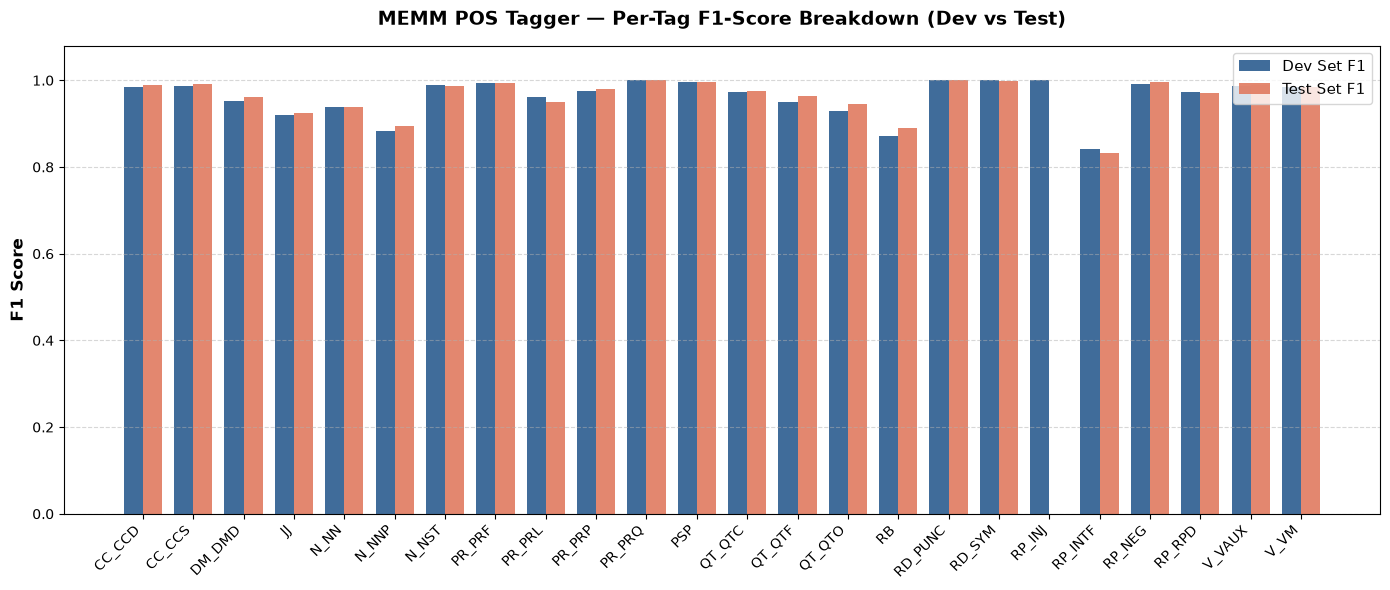

In [11]:
# Plot Per-Tag F1 Score on Dev vs Test
fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(all_tags))
width = 0.38

dev_f1s = [dev_tag_df.loc[dev_tag_df['tag'] == t, 'f1'].values[0] if t in dev_tag_df['tag'].values else 0 for t in all_tags]
test_f1s = [test_tag_df.loc[test_tag_df['tag'] == t, 'f1'].values[0] if t in test_tag_df['tag'].values else 0 for t in all_tags]

rects1 = ax.bar(x - width/2, dev_f1s, width, label='Dev Set F1', color='#2b5c8f', alpha=0.9)
rects2 = ax.bar(x + width/2, test_f1s, width, label='Test Set F1', color='#e07a5f', alpha=0.9)

ax.set_ylabel('F1 Score', fontsize=12, fontweight='bold')
ax.set_title('MEMM POS Tagger — Per-Tag F1-Score Breakdown (Dev vs Test)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(all_tags, rotation=45, ha='right', fontsize=10)
ax.set_ylim(0, 1.08)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig('memm_per_tag_f1.png', dpi=300)
plt.show()